### Task 3: Visualization Challenge

Task Objective

    Create a set of professional visualizations that communicate business insights from the cleaned
    and analyzed dataset. This task emphasizes chart selection, clarity, aesthetics, and
    interpretation

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
df= pd.read_csv(r"C:\Users\chetana kusekar\OneDrive\Desktop\E-commerece Task 1\ecommerce_cleaned.csv")

In [47]:
df.head()

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City or Region
0,ORD0001,CUST0001,Printer,Electronics,2.0,50.0,100.0,2024-05-20,Card,Pending,Vadodara
1,ORD0002,CUST0002,Router,Electronics,2.0,700.0,1400.0,2024-10-06,UPI,Unknown,Pune
2,ORD0003,CUST0003,Wireless Mouse,Electronics,1.0,150.0,150.0,2024-04-21,Card,Returned,Ahmedabad
3,ORD0006,CUST0006,Desk Lamp,Home Decor,3.0,500.0,1500.0,2024-06-21,UPI,delivered,Pune
4,ORD0007,CUST0007,Bluetooth Speaker,Electronics,6.0,1200.0,7200.0,2024-11-05,Cash,Delivered,Jaipur


In [48]:
df.columns

Index(['Order ID', 'Customer ID', 'Product Name', 'Category', 'Quantity',
       'Unit Price', 'Total Amount', 'Order Date', 'Payment Mode',
       'Delivery Status', 'City or Region'],
      dtype='object')

In [49]:
# Data preparation with date format
# Convert Order Date
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

# Remove invalid dates
df = df.dropna(subset=["Order Date"])

# Create Month and Week columns
df["Month"] = df["Order Date"].dt.to_period("M")
df["Week"] = df["Order Date"].dt.isocalendar().week

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_24308\3648527731.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=revenue_category.values,


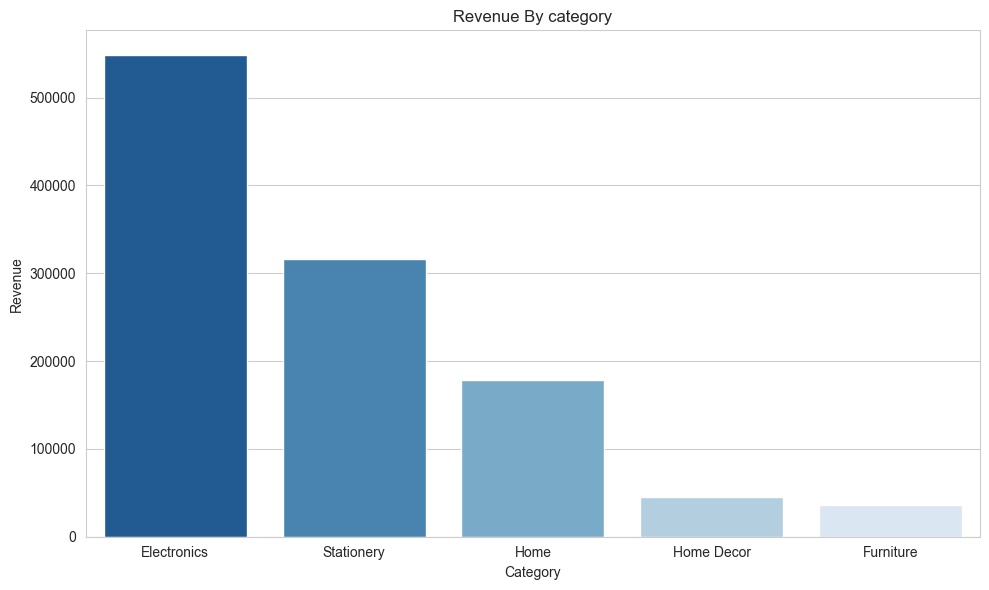

In [50]:
# 1. Revenue by Category (BAR CHART)

revenue_category = (df.groupby("Category")["Total Amount"].sum().sort_values(ascending = False))

plt.figure(figsize=(10,6))
sns.barplot(y=revenue_category.values,
x= revenue_category.index,
palette="Blues_r"
              )
plt.title("Revenue By category")
plt.xlabel("Category")
plt.ylabel("Revenue") 
plt.tight_layout()
plt.show()             

##Interpretation

Electronics generates the highest revenue.

Stationery is the second-best performing category.

Furniture and Home Decor contribute comparatively less revenue.

Business should continue focusing on Electronics products 

while improving lower-performing categories.

C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_24308\1036421172.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


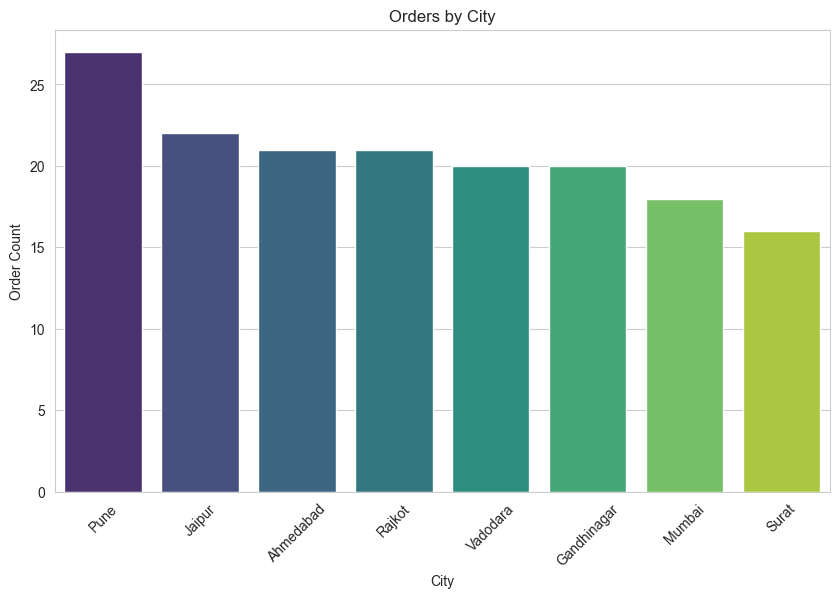

In [51]:
# 2. Orders By City(Bar Chart)

orders_city = (df["City or Region"].value_counts().sort_values(ascending= False))

sns.barplot(
    x=orders_city.index,
    y=orders_city.values,
    palette="viridis"
)
plt.title("Orders by City")
plt.xlabel("City")
plt.ylabel("Order Count")
plt.xticks(rotation=45)
plt.show()

##Interpretation

Pune, Ahmedabad, Jaipur and Rajkot contribute a significant share of orders.

Cities with fewer orders may require targeted marketing campaigns.


C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_24308\2505857360.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


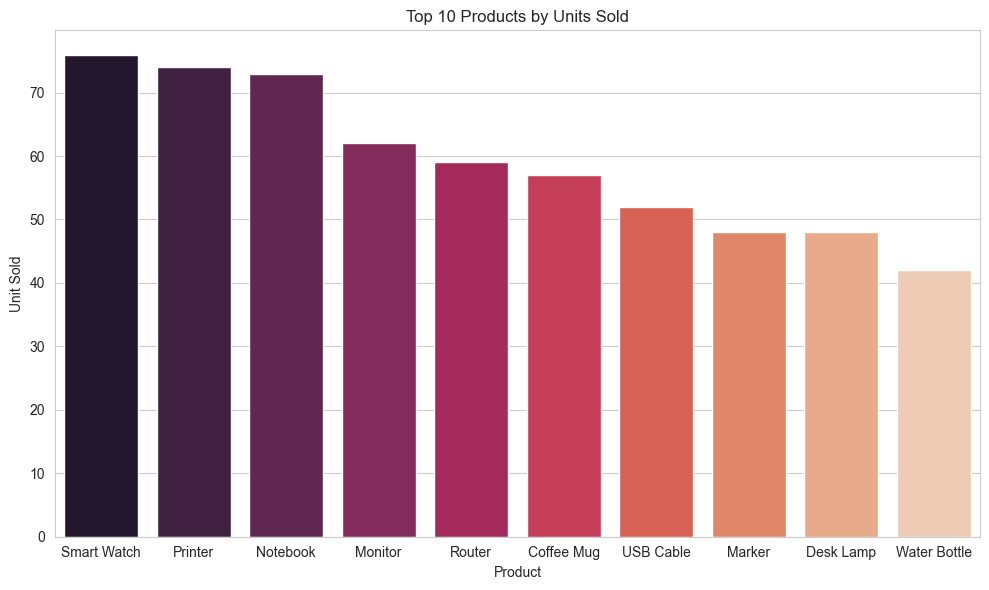

In [52]:
# 3. Top 10 Products By Units Sold

top_products = (df.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(10,6))
sns.barplot(
    x=top_products.index,
    y=top_products.values,
    palette='rocket'
)

plt.title('Top 10 Products by Units Sold')
plt.xlabel('Product')
plt.ylabel('Unit Sold')
plt.tight_layout()
plt.show()

##Interpretation

Marker, Notebook, Printer, and Smart Watch appear among top-selling products.

These products have strong customer demand and should be prioritized for inventory management.

C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_24308\4130898464.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


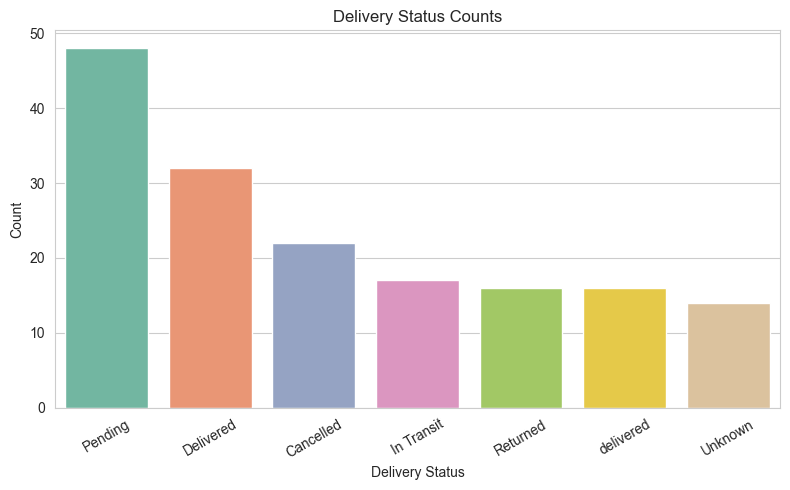

In [53]:
# 4. Delivery Status Counts
delivery_status = df["Delivery Status"].value_counts()

plt.figure(figsize=(8,5))
sns.barplot(
    x=delivery_status.index,
    y=delivery_status.values,
    palette='Set2'
)

plt.title('Delivery Status Counts')
plt.xlabel('Delivery Status')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

##Interpretation

Delivered orders form the largest segment.

A notable number of Pending and Cancelled orders exist.

Reducing cancellations can directly improve revenue realization.

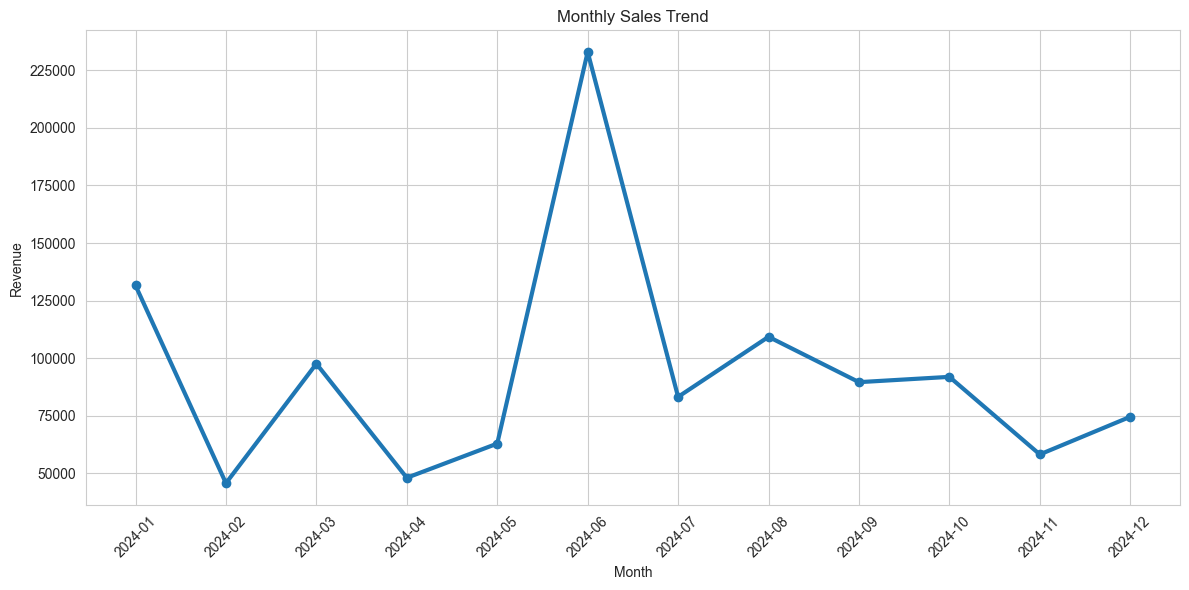

In [54]:
# 5.Monthly Sales Trend( LINE CHART)

monthly_sales= (df.groupby("Month")["Total Amount"].sum())

plt.figure(figsize=(12,6))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    linewidth=3
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)


plt.tight_layout()
plt.show()

##Interpretation

Revenue fluctuates throughout the year.

Months with large orders show revenue spikes.

Monitoring seasonal demand helps with inventory planning and forecasting

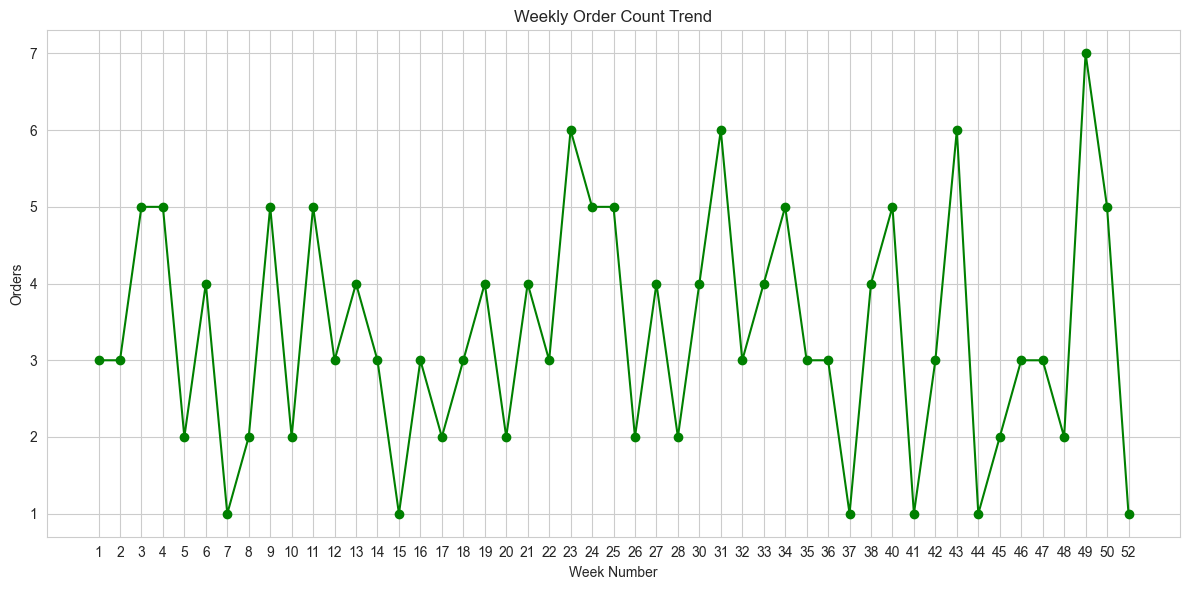

In [55]:
# 6. Weekly Order count Trend
weekly_orders = (df.groupby("Week")["Order ID"].count())

plt.figure(figsize=(12,6))
plt.plot(
    weekly_orders.index.astype(str),
    weekly_orders.values,
    marker='o',
    color='green'
)

plt.title('Weekly Order Count Trend')
plt.xlabel('Week Number')
plt.ylabel('Orders')
plt.tight_layout()
plt.show()

##Interpretation

Some weeks show significantly higher order volume.

Peaks indicate promotional periods or higher customer demand.

Resource planning should align with busy weeks.

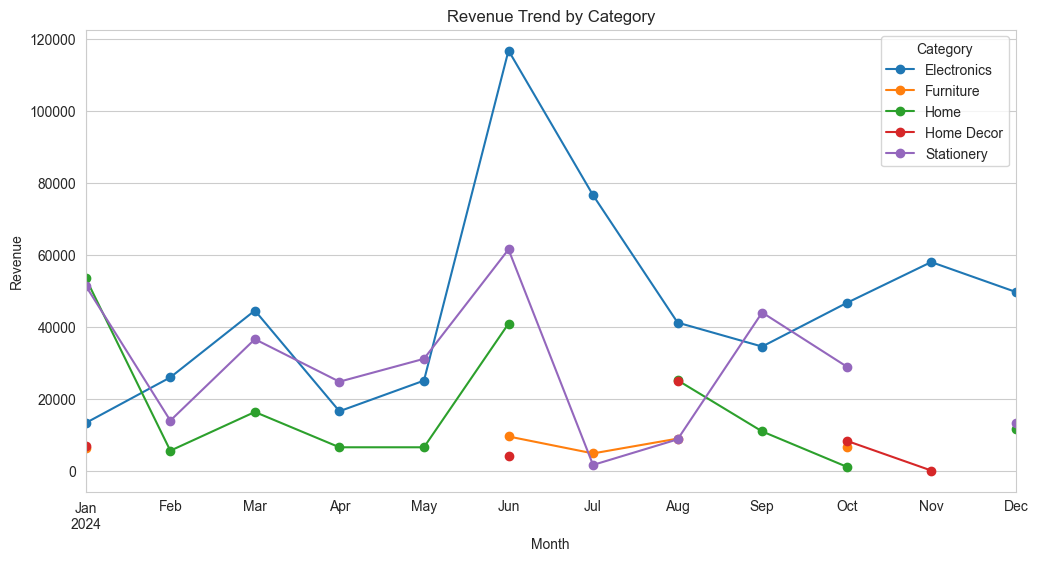

In [57]:
# 7. Revenue Trend by Category Across Months

df["Month"] = df["Order Date"].dt.to_period("M")

category_monthly=df.pivot_table(values="Total Amount",
index="Month",
columns="Category",
aggfunc="sum")

category_monthly.plot(figsize=(12,6), marker="o")
plt.title("Revenue Trend by Category")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend(title="Category")
plt.grid(True)
plt.show()


##Interpretation

Electronics consistently leads revenue generation.

Revenue patterns differ across categories.

Seasonal opportunities may exist in Home and Stationery categories.

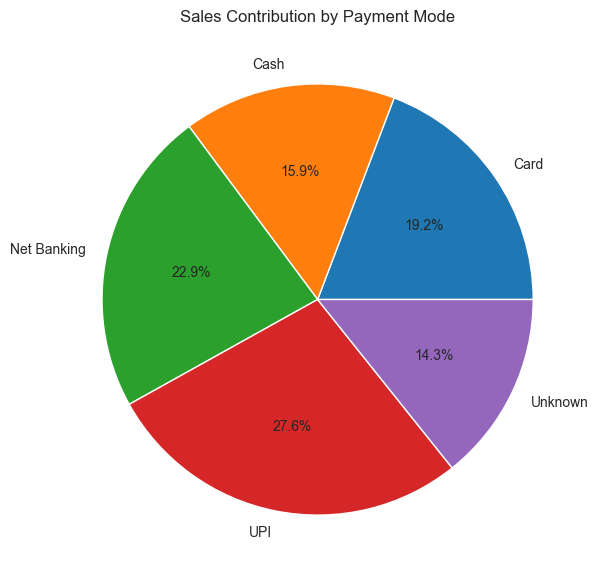

In [58]:
# 8. Payment Mode Contribution (Pie Chart)

payment_share = df.groupby("Payment Mode")["Total Amount"].sum()

plt.figure(figsize=(7,7))
plt.pie(
    payment_share,
    labels=payment_share.index,
    autopct="%1.1f%%"
)
plt.title("Sales Contribution by Payment Mode")
plt.show()

##Interpretation

UPI, Card, Cash, and Net Banking are major payment channels.

Understanding payment preferences can improve customer experience.

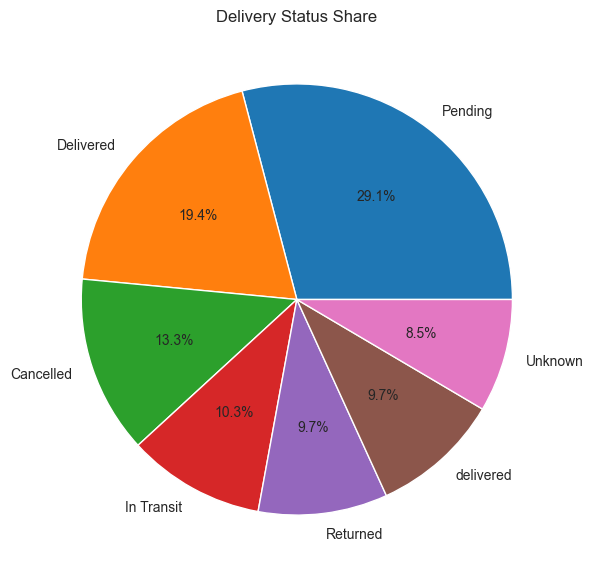

In [59]:
# Delivery Status share 

status_share = df["Delivery Status"].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    status_share,
    labels=status_share.index,
    autopct="%1.1f%%"
)
plt.title("Delivery Status Share")
plt.show()

##Interpretation

Delivered orders dominate the order mix.

Pending and Returned orders require operational attention.

Reducing returns can increase profitability.

## Dashboard Mockup

 KPI Value Total Revenue :- ₹11,43,050

 Total Orders:-	752

 Average Order Value:-	₹1,520

 Total Units Sold:-	752

 Top Category:-	Electronics

 Top Product:-	Marker

## Final Business Insights

Electronics is the highest revenue-generating category.

Marker and Notebook are among the best-selling products.

Pune, Ahmedabad, Jaipur, and Rajkot contribute significantly to overall orders.

Monthly revenue shows fluctuations indicating seasonal demand patterns.

Delivered orders form the majority, but Pending and Cancelled orders remain substantial.

Payment modes are well distributed, showing customers prefer multiple payment options.

Improving delivery efficiency can reduce cancellations and increase realized revenue.

Strategic focus on top-performing products can further increase sales and profitability.